# Checkpoint 2: Same County, Different Weather? Comparing Four Prince George's County Weather Stations
Group Members & Contributions: 

Aashreya: Data Pre-Processing

Natalie, Dia, Jenny, Luna, Andy

## Part 1: Data Pre-processing

### Importing:

In [75]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats 

df = pd.read_csv("dailyweatherdata.csv")
df.head()

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,SNOW,SNWD,TMAX,TMIN
0,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-01,0.0,0.0,0.0,57.0,26.0
1,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-02,0.0,0.0,0.0,59.0,26.0
2,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-03,0.0,0.0,0.0,68.0,49.0
3,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-04,0.0,0.0,0.0,70.0,57.0
4,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-05,1.1,0.0,0.0,72.0,38.0


 df.dtypes

### Parse:

In [78]:
# string to date, then pulling out year and month as ints
df["DATE"] = pd.to_datetime(df["DATE"])
df["YEAR"] = df["DATE"].dt.year
df["MONTH"] = df["DATE"].dt.month

#find any impossible rows (ex: low temp higher than the high temp)
bad = df[df["TMIN"] > df["TMAX"]]
print("Rows where TMIN > TMAX:", len(bad))
bad[["NAME", "DATE", "TMAX", "TMIN"]]

Rows where TMIN > TMAX: 5


,NAME,DATE,TMAX,TMIN
6986,"BELTSVILLE, MD US",2002-07-22,22.0,69.0
8386,"BELTSVILLE, MD US",2006-05-22,73.0,74.0
8717,"BELTSVILLE, MD US",2007-04-18,35.0,42.0
9531,"BELTSVILLE, MD US",2009-07-10,10.0,59.0
22679,"LAUREL 3 W, MD US",2000-06-11,71.0,96.0


In [79]:
# Set temperatures to NaN on the days that are impossible
df.loc[df["TMIN"] > df["TMAX"], ["TMAX", "TMIN"]] = float("nan")

#check for duplicate rows (same station on the same day)
print("Duplicate station days:", df.duplicated(["STATION", "DATE"]).sum())

Duplicate station days: 0


### Organize

In [87]:
#simpler column names
df = df.rename(columns={"STATION": "station_id", "NAME": "station", "DATE": "date", "YEAR": "year", 
"MONTH": "month", "TMAX":"tmax", "TMIN":"tmin", "PRCP":"prcp", "SNOW": "snow",
"SNWD": "snow_depth", "LATITUDE": "lat", "LONGITUDE": "lon", "ELEVATION": "elevation"})


#shorter station names
df["station"] = df["station"].replace({"BELTSVILLE, MD US": "Beltsville", "LAUREL 3 W, MD US": "Laurel",
"OXON HILL, MD US": "Oxon Hill", "UPPER MARLBORO 3 NNW, MD US": "Upper Marlboro"})

#sort so each station's days are in order 
df = df.sort_values(["station","date"]).reset_index(drop=True)

# Mark each day as rainy (1) or dry (0) so we can try to predict if it'll rain
df["rain_day"] = (df["prcp"] > 0).astype(int)

# If rain wasn't recorded, we don't know, so leave it blank instead of calling it dry
df.loc[df["prcp"].isna(), "rain_day"] = float("nan")

# Add yesterday's low, since it's a good clue for predicting today's low
df["tmin_yesterday"] = df.groupby("station")["tmin"].shift(1)

df.head()

,station_id,station,lat,lon,elevation,date,prcp,snow,snow_depth,tmax,tmin,year,month,rain_day,tmin_yesterday
0,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-01,0.00,0.0,0.0,55.0,27.0,2000,1,0.0,NaN
1,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-02,0.00,0.0,0.0,52.0,27.0,2000,1,0.0,27.0
2,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-03,0.00,0.0,0.0,67.0,48.0,2000,1,0.0,27.0
3,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-04,0.00,0.0,0.0,67.0,57.0,2000,1,0.0,48.0
4,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-05,1.22,0.0,0.0,69.0,36.0,2000,1,1.0,57.0


### Exploratory Data Analysis

In [92]:
print("Number of entires:", df.shape[0])
print("Number of features:", df.shape[1])
print(df["station"].value_counts())

Number of entires: 28270
Number of features: 15
station
Beltsville        9482
Oxon Hill         6982
Upper Marlboro    6053
Laurel            5753
Name: count, dtype: int64


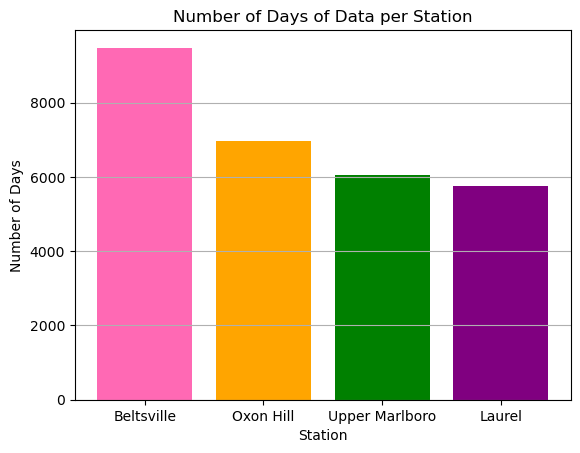

In [100]:
counts = df["station"].value_counts()
plt.figure
plt.bar(counts.index, counts.values, color=['hotpink', 'orange', 'green','purple'])
plt.title("Number of Days of Data per Station")
plt.xlabel("Station")
plt.ylabel("Number of Days")
plt.grid(axis="y")
plt.show()

In [102]:
# checking which years does each station has data for
pd.crosstab(df["year"], df["station"])

station,Beltsville,Laurel,Oxon Hill,Upper Marlboro
year,,,,
2000,366,366,0,366
2001,365,365,0,365
2002,365,365,213,365
2003,365,365,360,365
2004,366,366,362,366
2005,365,365,363,365
2006,365,335,365,335
2007,365,365,365,365
2008,366,366,366,366


In [104]:
# Fraction of missing values for each station
df.groupby("station")[["tmax", "tmin", "prcp", "snow", "snow_depth"]].apply(lambda g: g.isna().mean()).round(3)

,tmax,tmin,prcp,snow,snow_depth
station,,,,,
Beltsville,0.000,0.001,0.000,0.000,0.000
Laurel,0.242,0.243,0.066,0.257,0.303
Oxon Hill,0.012,0.011,0.004,0.008,0.019
Upper Marlboro,0.020,0.020,0.021,0.250,0.255


This dataset has 28,270 entries. Beltsville is overrepresented in the sample since it's the only station with data for all of the years. The other stations stopped reporting halfway through. Laurel is also missing about 24% of it's temperatures and Laurel and Upper Marlboro are missing about a quarter of their snow-depth values. Due to the stations not all having all of the years when we compare two stations we need to only sue dates both of them have. 

## Part 2: Summary Statistics

maybe compare average temps/rain by station or month, and check for outliers. FYI most days have 0 rain, so outlier stuff on prcp gets weird.

## Part 3: Correlation

try .corr() with a heatmap. I added tmin_yesterday, which might be interesting to look at since we could use it for the ML part.

## Part 4: Hypothesis Test

maybe test whether one station is warmer than another. The stations cover different years, so only compare dates both have (merge on date).